# Exploratory Data Analysis: E-Commerce Customer Churn

**Project:** Explainable Customer Churn Prediction for E-Commerce using XGBoost and SHAP

**Goal of this notebook:** understand the data before modelling. We check data quality (missing values, duplicates, inconsistent labels, outliers), study how each feature relates to churn, and save a cleaned dataset for training.

**Dataset:** [E-Commerce Customer Churn Analysis and Prediction](https://www.kaggle.com/datasets/ankitverma2010/ecommerce-customer-churn-analysis-and-prediction) (Kaggle). Each row is one customer of an online retail company. `Churn = 1` means the customer left.

## 1. Setup

In [1]:
import sys
from pathlib import Path

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
import seaborn as sns

ROOT = Path.cwd().parent if Path.cwd().name == "notebooks" else Path.cwd()
sys.path.insert(0, str(ROOT))

from src.config import CATEGORICAL_FEATURES, NUMERIC_FEATURES, RAW_DATA_PATH, CLEAN_DATA_PATH, TARGET
from src.data_prep import load_raw, clean, CATEGORY_FIXES

sns.set_theme(style="whitegrid", palette="Set2")
plt.rcParams["figure.dpi"] = 100
pd.set_option("display.max_columns", 30)

## 2. Load the data
The Excel file has two sheets: a data dictionary and the actual data (`E Comm`).

In [2]:
dictionary = pd.read_excel(RAW_DATA_PATH, sheet_name=0)
dictionary

,Unnamed: 0,Unnamed: 1,Unnamed: 2,Unnamed: 3
0,NaN,Data,Variable,Discerption
1,NaN,E Comm,CustomerID,Unique customer ID
2,NaN,E Comm,Churn,Churn Flag
3,NaN,E Comm,Tenure,Tenure of customer in organization
4,NaN,E Comm,PreferredLoginDevice,Preferred login device of customer
5,NaN,E Comm,CityTier,City tier
6,NaN,E Comm,WarehouseToHome,Distance in between warehouse to home of customer
7,NaN,E Comm,PreferredPaymentMode,Preferred payment method of customer
8,NaN,E Comm,Gender,Gender of customer
9,NaN,E Comm,HourSpendOnApp,Number of hours spend on mobile application or...


In [3]:
df = load_raw()
print("Shape:", df.shape)
df.head()

Shape: (5630, 20)


,CustomerID,Churn,Tenure,PreferredLoginDevice,CityTier,WarehouseToHome,PreferredPaymentMode,Gender,HourSpendOnApp,NumberOfDeviceRegistered,PreferedOrderCat,SatisfactionScore,MaritalStatus,NumberOfAddress,Complain,OrderAmountHikeFromlastYear,CouponUsed,OrderCount,DaySinceLastOrder,CashbackAmount
0,50001,1,4.0,Mobile Phone,3,6.0,Debit Card,Female,3.0,3,Laptop & Accessory,2,Single,9,1,11.0,1.0,1.0,5.0,159.93
1,50002,1,NaN,Phone,1,8.0,UPI,Male,3.0,4,Mobile,3,Single,7,1,15.0,0.0,1.0,0.0,120.90
2,50003,1,NaN,Phone,1,30.0,Debit Card,Male,2.0,4,Mobile,3,Single,6,1,14.0,0.0,1.0,3.0,120.28
3,50004,1,0.0,Phone,3,15.0,Debit Card,Male,2.0,4,Laptop & Accessory,5,Single,8,0,23.0,0.0,1.0,3.0,134.07
4,50005,1,0.0,Phone,1,12.0,CC,Male,NaN,3,Mobile,5,Single,3,0,11.0,1.0,1.0,3.0,129.60


In [4]:
df.info()

<class 'pandas.DataFrame'>
RangeIndex: 5630 entries, 0 to 5629
Data columns (total 20 columns):
 #   Column                       Non-Null Count  Dtype  
---  ------                       --------------  -----  
 0   CustomerID                   5630 non-null   int64  
 1   Churn                        5630 non-null   int64  
 2   Tenure                       5366 non-null   float64
 3   PreferredLoginDevice         5630 non-null   str    
 4   CityTier                     5630 non-null   int64  
 5   WarehouseToHome              5379 non-null   float64
 6   PreferredPaymentMode         5630 non-null   str    
 7   Gender                       5630 non-null   str    
 8   HourSpendOnApp               5375 non-null   float64
 9   NumberOfDeviceRegistered     5630 non-null   int64  
 10  PreferedOrderCat             5630 non-null   str    
 11  SatisfactionScore            5630 non-null   int64  
 12  MaritalStatus                5630 non-null   str    
 13  NumberOfAddress              

In [5]:
df.describe().T.round(2)

,count,mean,std,min,25%,50%,75%,max
CustomerID,5630.0,52815.50,1625.39,50001.0,51408.25,52815.50,54222.75,55630.00
Churn,5630.0,0.17,0.37,0.0,0.00,0.00,0.00,1.00
Tenure,5366.0,10.19,8.56,0.0,2.00,9.00,16.00,61.00
CityTier,5630.0,1.65,0.92,1.0,1.00,1.00,3.00,3.00
WarehouseToHome,5379.0,15.64,8.53,5.0,9.00,14.00,20.00,127.00
HourSpendOnApp,5375.0,2.93,0.72,0.0,2.00,3.00,3.00,5.00
NumberOfDeviceRegistered,5630.0,3.69,1.02,1.0,3.00,4.00,4.00,6.00
SatisfactionScore,5630.0,3.07,1.38,1.0,2.00,3.00,4.00,5.00
NumberOfAddress,5630.0,4.21,2.58,1.0,2.00,3.00,6.00,22.00
Complain,5630.0,0.28,0.45,0.0,0.00,0.00,1.00,1.00


**Observation:** The dataset has 5,630 customers and 20 columns (1 ID, 1 target, 18 features). 13 features are numeric and 5 are text categories. Most values look sensible: average tenure is about 10 months, average cashback is about Rs 177, and 28% of customers raised a complaint last month. Seven columns have missing values, so cleaning is needed before modelling.

## 3. Data quality checks
### 3.1 Missing values

,missing,percent
DaySinceLastOrder,307,5.45
OrderAmountHikeFromlastYear,265,4.71
Tenure,264,4.69
OrderCount,258,4.58
CouponUsed,256,4.55
HourSpendOnApp,255,4.53
WarehouseToHome,251,4.46


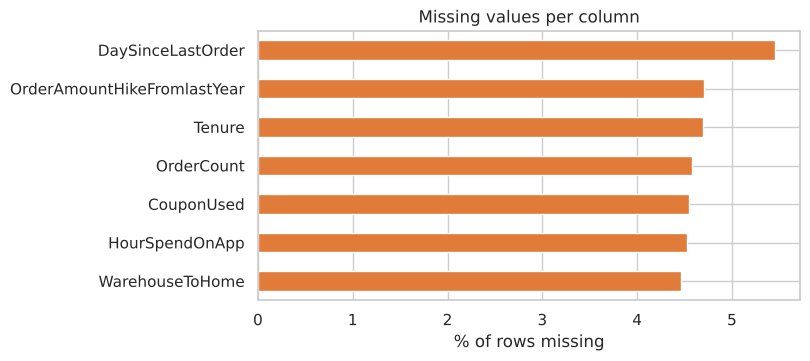

In [6]:
missing = df.isna().sum()
missing = missing[missing > 0].sort_values(ascending=False)
missing_table = pd.DataFrame({"missing": missing, "percent": (missing / len(df) * 100).round(2)})
display(missing_table)

ax = missing_table["percent"].plot(kind="barh", figsize=(7, 3.5), color="#e07b39")
ax.set_xlabel("% of rows missing")
ax.set_title("Missing values per column")
ax.invert_yaxis()
plt.show()

In [7]:
# Is missingness linked to churn? Compare churn rate where the value is missing vs present.
pd.DataFrame({
    col: {"churn rate if missing": df.loc[df[col].isna(), TARGET].mean(),
          "churn rate if present": df.loc[df[col].notna(), TARGET].mean()}
    for col in missing.index
}).T.round(3)

,churn rate if missing,churn rate if present
DaySinceLastOrder,0.176,0.168
OrderAmountHikeFromlastYear,0.053,0.174
Tenure,0.307,0.162
OrderCount,0.070,0.173
CouponUsed,0.031,0.175
HourSpendOnApp,0.227,0.166
WarehouseToHome,0.335,0.161


**Observation:** Seven numeric columns have 4.5% to 5.5% missing values each, so no column needs to be dropped. The missing values are not random. Customers with a missing Tenure churn at 30.7% (vs 16.2% when present) and a missing WarehouseToHome churns at 33.5% (vs 16.1%). Simply deleting these rows would remove a lot of churners, so we keep them and fill the gaps with the median inside the model pipeline.

### 3.2 Duplicates

In [8]:
print("Duplicate rows (all columns):", df.duplicated().sum())
print("Duplicate CustomerIDs:", df["CustomerID"].duplicated().sum())
print("Duplicate rows ignoring CustomerID:", df.drop(columns="CustomerID").duplicated().sum())

Duplicate rows (all columns): 0
Duplicate CustomerIDs: 0
Duplicate rows ignoring CustomerID: 556


**Observation:** There are no duplicate CustomerIDs, but 556 rows are exact copies of another customer apart from the ID (557 after the label fixes below). If kept, the same customer could appear in both the training and the test set, which would make the test scores look better than they really are. These duplicates are removed.

### 3.3 Inconsistent category labels

In [9]:
for col in CATEGORICAL_FEATURES:
    print(f"{col}:")
    print(df[col].value_counts().to_string(), "\n")

PreferredLoginDevice:
PreferredLoginDevice
Mobile Phone    2765
Computer        1634
Phone           1231 

PreferredPaymentMode:
PreferredPaymentMode
Debit Card          2314
Credit Card         1501
E wallet             614
UPI                  414
COD                  365
CC                   273
Cash on Delivery     149 

Gender:
Gender
Male      3384
Female    2246 

PreferedOrderCat:
PreferedOrderCat
Laptop & Accessory    2050
Mobile Phone          1271
Fashion                826
Mobile                 809
Grocery                410
Others                 264 

MaritalStatus:
MaritalStatus
Married     2986
Single      1796
Divorced     848 



In [10]:
print("Fixes applied in src/data_prep.py:")
for col, mapping in CATEGORY_FIXES.items():
    for old, new in mapping.items():
        print(f"  {col}: '{old}' -> '{new}'")

Fixes applied in src/data_prep.py:
  PreferredLoginDevice: 'Phone' -> 'Mobile Phone'
  PreferredPaymentMode: 'CC' -> 'Credit Card'
  PreferredPaymentMode: 'COD' -> 'Cash on Delivery'
  PreferedOrderCat: 'Mobile' -> 'Mobile Phone'


**Observation:** Three columns use different spellings for the same thing: 'Phone' and 'Mobile Phone' for login device, 'CC' and 'Credit Card' or 'COD' and 'Cash on Delivery' for payment, and 'Mobile' and 'Mobile Phone' for order category. Without fixing these, the model would treat one category as two separate ones. After merging, login device has 2 values, payment mode has 5 and order category has 5.

### 3.4 Clean the data
We use the same `clean()` function that the training script uses, so the notebook and the model always see identical data.

Missing values are **not** filled here. They are filled inside the model pipeline using medians from the training set only, which avoids leaking test-set information into training.

In [11]:
data = clean(df)
print("Rows before:", len(df), "| after:", len(data))
for col in CATEGORICAL_FEATURES:
    print(f"{col}: {sorted(data[col].dropna().unique())}")

Rows before: 5630 | after: 5073
PreferredLoginDevice: ['Computer', 'Mobile Phone']
PreferredPaymentMode: ['Cash on Delivery', 'Credit Card', 'Debit Card', 'E wallet', 'UPI']
Gender: ['Female', 'Male']
PreferedOrderCat: ['Fashion', 'Grocery', 'Laptop & Accessory', 'Mobile Phone', 'Others']
MaritalStatus: ['Divorced', 'Married', 'Single']


### 3.5 Outliers (IQR rule)

,outliers
OrderCount,673
CouponUsed,610
CashbackAmount,382
NumberOfDeviceRegistered,363
DaySinceLastOrder,57
OrderAmountHikeFromlastYear,29
HourSpendOnApp,6
Tenure,4
NumberOfAddress,4
WarehouseToHome,2


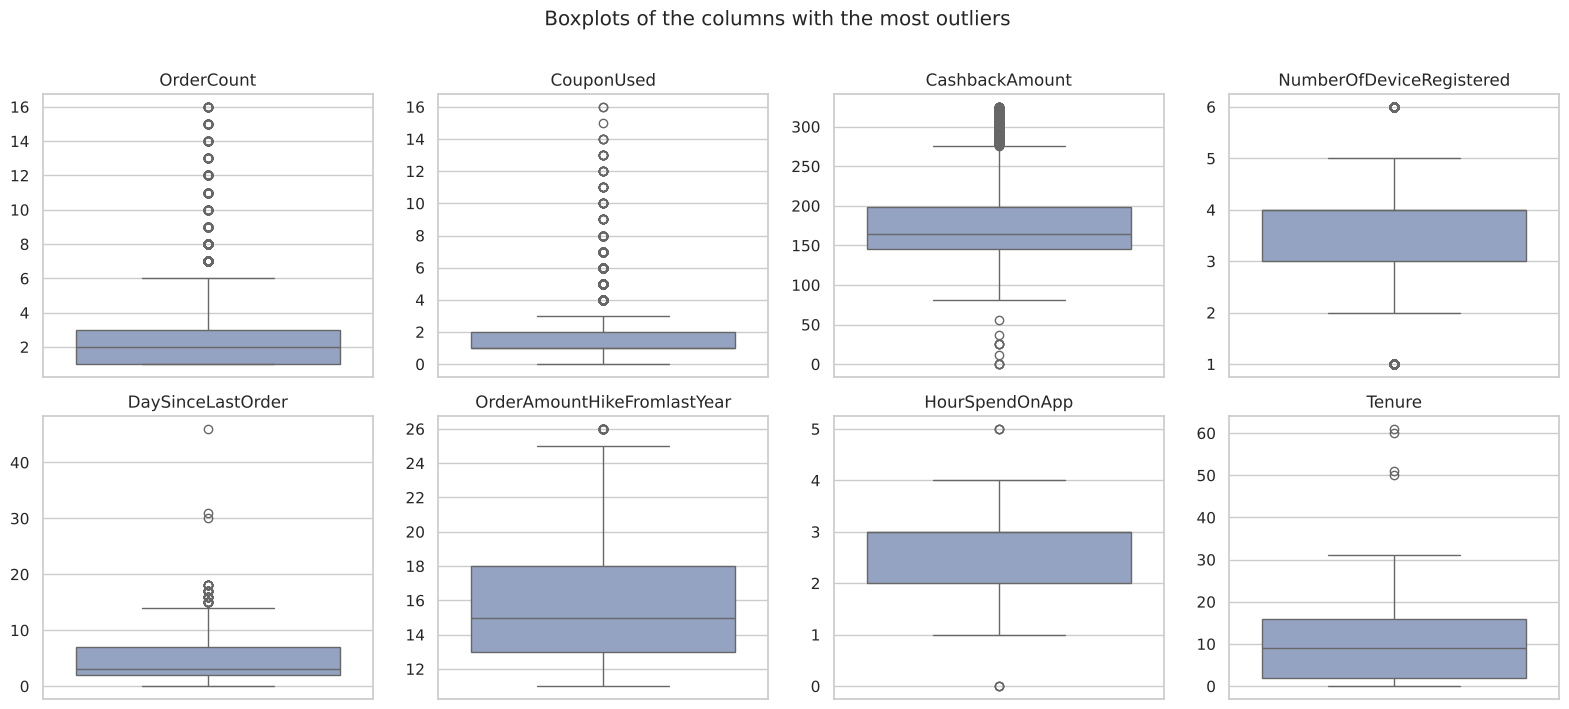

In [12]:
def iqr_outliers(s):
    q1, q3 = s.quantile([0.25, 0.75])
    iqr = q3 - q1
    return ((s < q1 - 1.5 * iqr) | (s > q3 + 1.5 * iqr)).sum()

out = pd.Series({c: iqr_outliers(data[c].dropna()) for c in NUMERIC_FEATURES}).sort_values(ascending=False)
display(out[out > 0].to_frame("outliers"))

fig, axes = plt.subplots(2, 4, figsize=(16, 7))
for ax, col in zip(axes.flat, out.index[:8]):
    sns.boxplot(y=data[col], ax=ax, color="#8da0cb")
    ax.set_title(col)
    ax.set_ylabel("")
plt.suptitle("Boxplots of the columns with the most outliers", y=1.01)
plt.tight_layout()
plt.show()

**Observation:** OrderCount, CouponUsed, CashbackAmount and NumberOfDeviceRegistered show the most IQR outliers. Looking at the boxplots, these are believable values (for example a loyal customer placing 16 orders in a month), not data entry errors, so they are kept. Tree-based models like Random Forest and XGBoost are not much affected by outliers.

## 4. Target variable

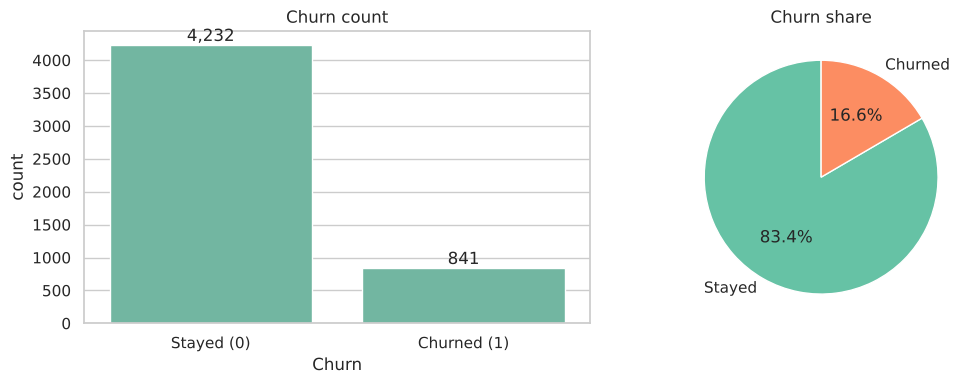

Churn rate: 16.58%


In [13]:
counts = data[TARGET].value_counts().sort_index()
fig, axes = plt.subplots(1, 2, figsize=(11, 4))
sns.countplot(x=TARGET, data=data, ax=axes[0])
axes[0].set_xticks([0, 1], ["Stayed (0)", "Churned (1)"])
for p in axes[0].patches:
    axes[0].annotate(f"{int(p.get_height()):,}", (p.get_x() + p.get_width() / 2, p.get_height()),
                     ha="center", va="bottom")
axes[0].set_title("Churn count")
axes[1].pie(counts, labels=["Stayed", "Churned"], autopct="%1.1f%%", startangle=90,
            colors=["#66c2a5", "#fc8d62"])
axes[1].set_title("Churn share")
plt.tight_layout()
plt.show()
print(f"Churn rate: {data[TARGET].mean():.2%}")

**Observation:** After cleaning, 16.6% of customers churned and 83.4% stayed, so the classes are imbalanced. A model that always predicts 'stayed' would already get about 83% accuracy while catching zero churners. This is why accuracy alone is misleading here, and why we focus on F1-score, recall, ROC-AUC and the confusion matrix, and use class weights during training.

## 5. Numeric features vs churn

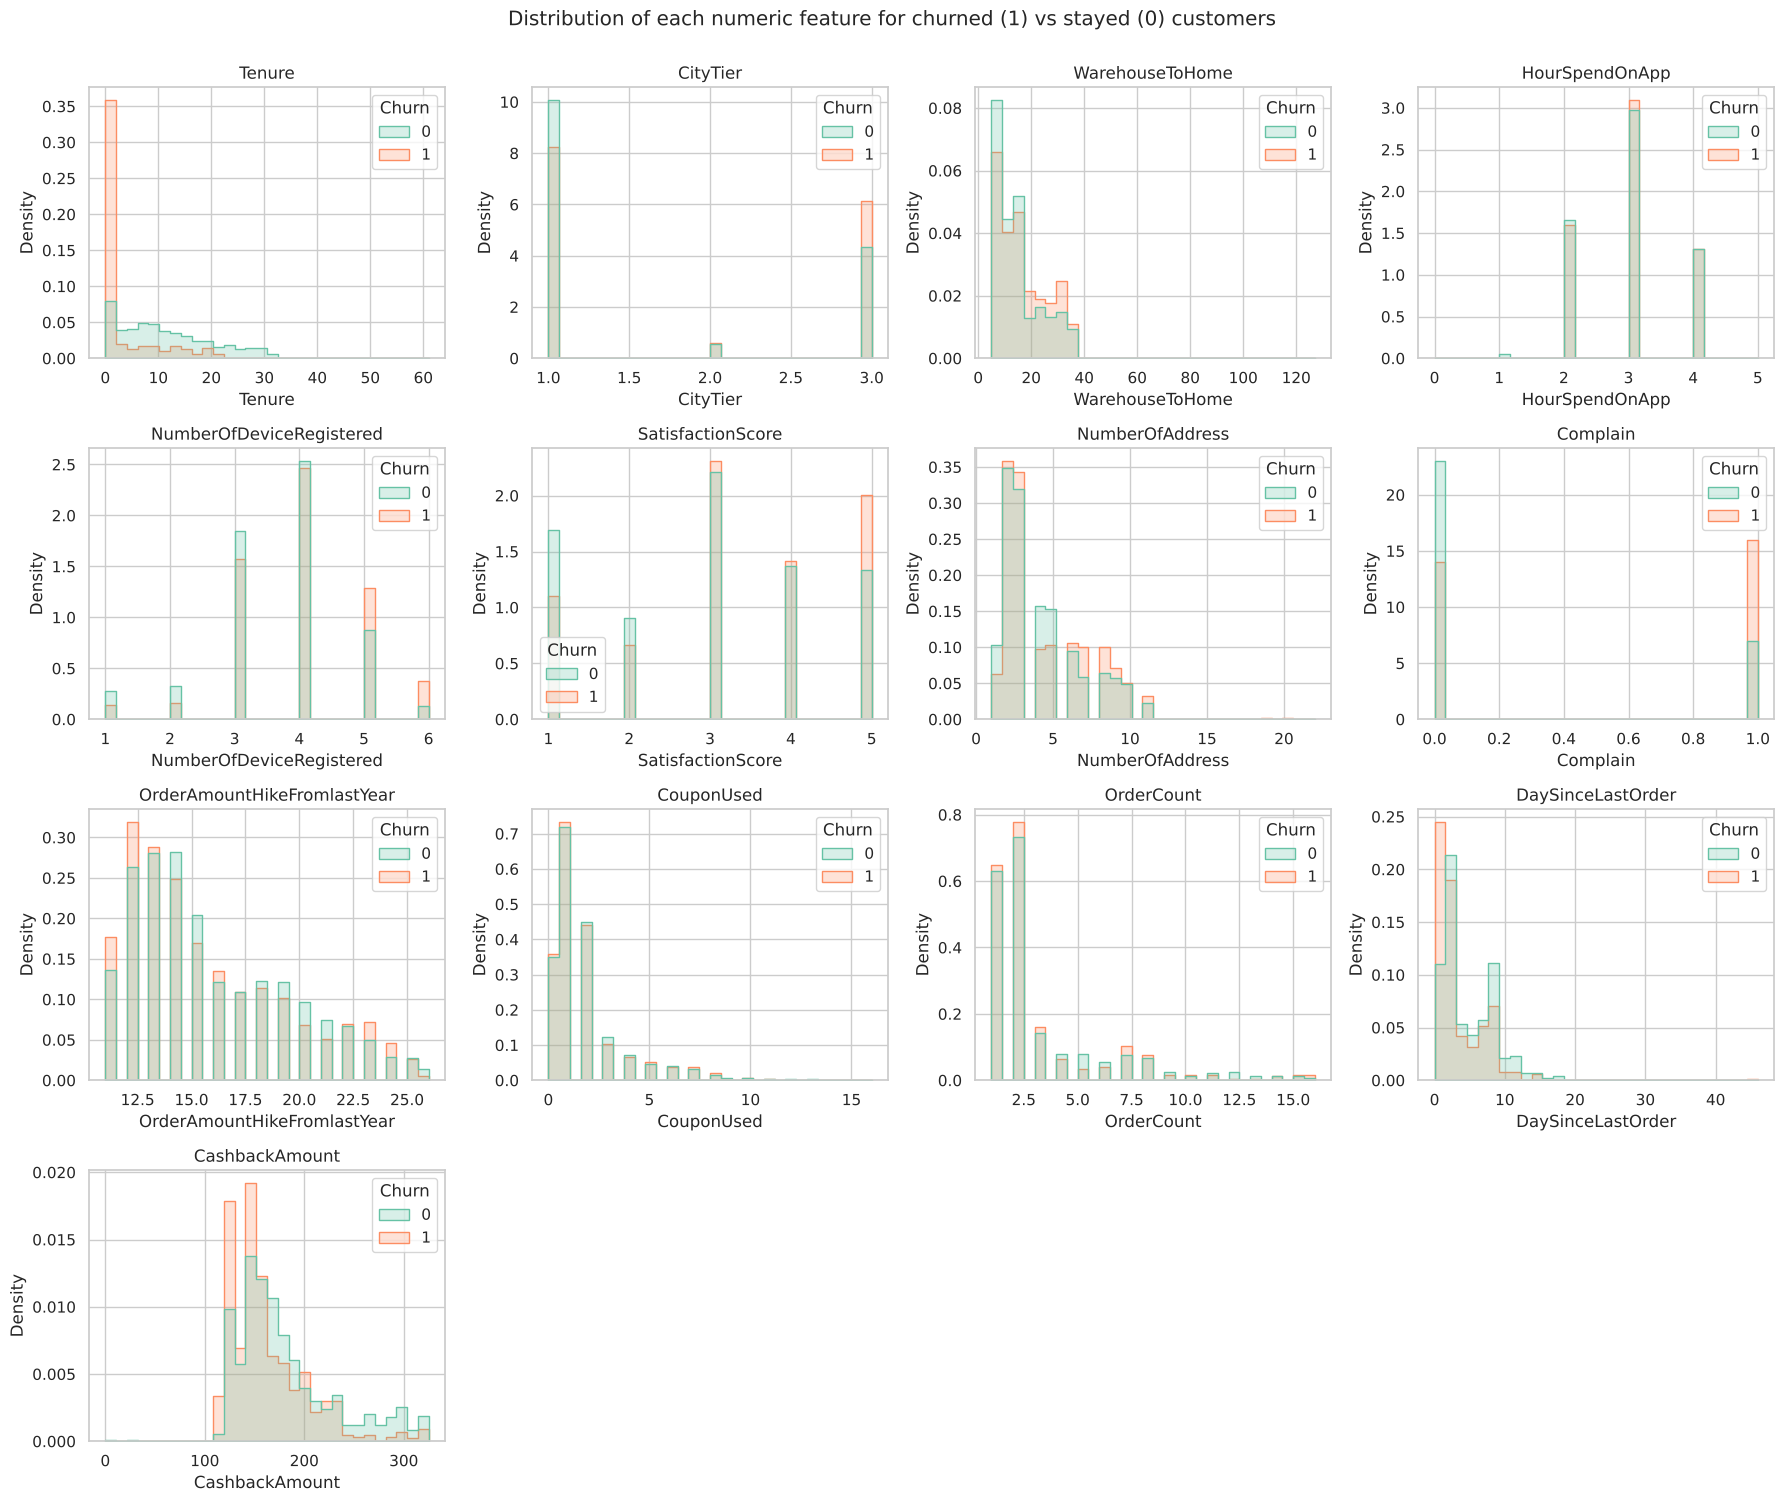

In [14]:
fig, axes = plt.subplots(4, 4, figsize=(18, 15))
for ax, col in zip(axes.flat, NUMERIC_FEATURES):
    sns.histplot(data=data, x=col, hue=TARGET, stat="density", common_norm=False,
                 element="step", bins=30, ax=ax)
    ax.set_title(col)
for ax in axes.flat[len(NUMERIC_FEATURES):]:
    ax.remove()
plt.suptitle("Distribution of each numeric feature for churned (1) vs stayed (0) customers", y=1.0)
plt.tight_layout()
plt.show()

In [15]:
# Median of each numeric feature for stayed vs churned customers
data.groupby(TARGET)[NUMERIC_FEATURES].median().T.rename(columns={0: "Stayed", 1: "Churned"})

Churn,Stayed,Churned
Tenure,10.00,1.0
CityTier,1.00,1.0
WarehouseToHome,13.00,15.0
HourSpendOnApp,3.00,3.0
NumberOfDeviceRegistered,4.00,4.0
SatisfactionScore,3.00,3.0
NumberOfAddress,3.00,3.0
Complain,0.00,1.0
OrderAmountHikeFromlastYear,15.00,14.0
CouponUsed,1.00,1.0


**Observation:** The biggest difference is in Tenure: the median churned customer has been with the company for only 1 month, compared to 10 months for those who stayed. Churned customers also have lower cashback (median Rs 151 vs Rs 166), placed their last order more recently (2 vs 4 days) and live slightly farther from the warehouse (15 vs 13 km). Complaints stand out clearly: the median churner raised a complaint. Features like HourSpendOnApp, CouponUsed and OrderCount look almost the same for both groups.

### 5.1 Tenure: how long the customer has been with the company

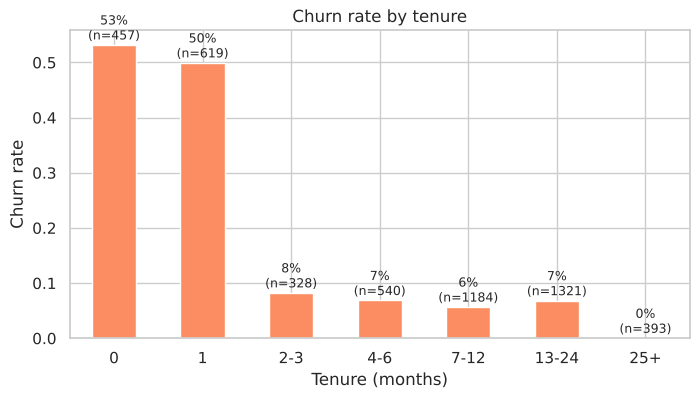

In [16]:
bins = [-1, 0, 1, 3, 6, 12, 24, 100]
labels = ["0", "1", "2-3", "4-6", "7-12", "13-24", "25+"]
tenure_group = pd.cut(data["Tenure"], bins=bins, labels=labels)
rate = data.groupby(tenure_group, observed=True)[TARGET].agg(["mean", "size"])
ax = rate["mean"].plot(kind="bar", figsize=(8, 4), color="#fc8d62", rot=0)
ax.set_xlabel("Tenure (months)")
ax.set_ylabel("Churn rate")
ax.set_title("Churn rate by tenure")
for i, (m, n) in enumerate(zip(rate["mean"], rate["size"])):
    ax.text(i, m + 0.01, f"{m:.0%}\n(n={n})", ha="center", fontsize=9)
plt.show()

**Observation:** Churn is concentrated in brand-new customers. About 53% of customers with tenure 0 and 50% with tenure 1 churned, but this drops to around 6 to 8% after the third month, and none of the 393 customers with 25+ months churned. The first one to two months are the most critical period for retention.

## 6. Churn rate by category

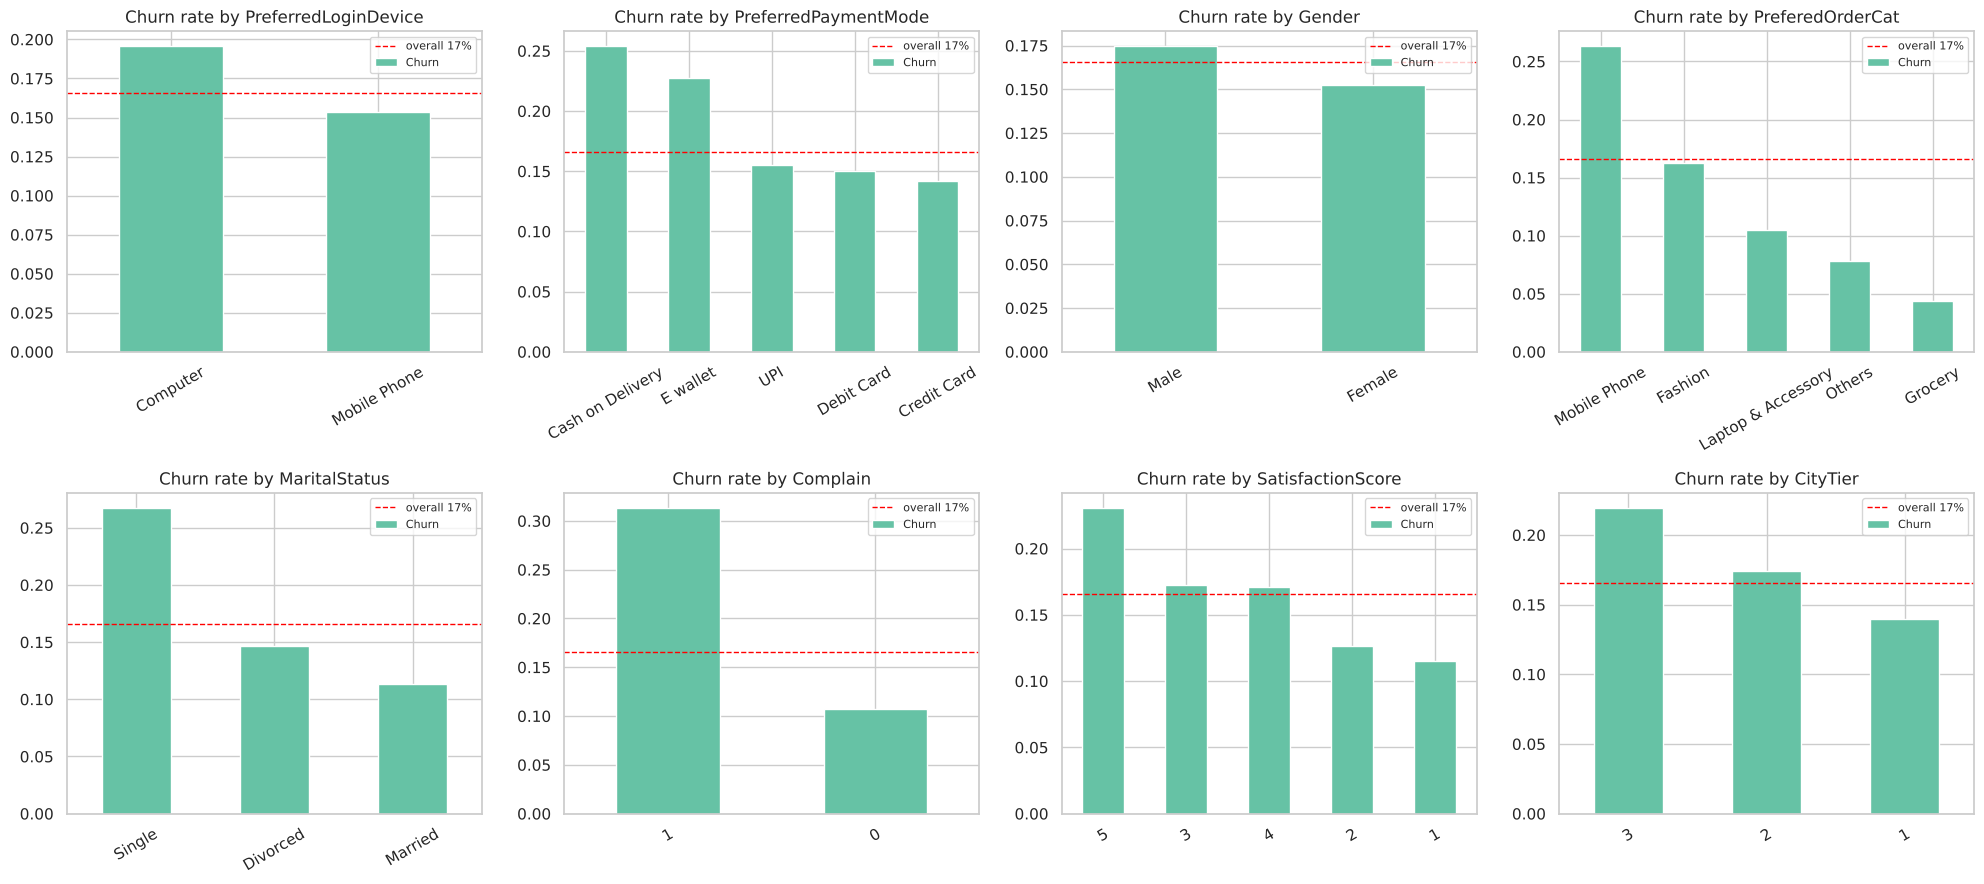

In [17]:
cols = CATEGORICAL_FEATURES + ["Complain", "SatisfactionScore", "CityTier"]
fig, axes = plt.subplots(2, 4, figsize=(20, 9))
overall = data[TARGET].mean()
for ax, col in zip(axes.flat, cols):
    rate = data.groupby(col)[TARGET].mean().sort_values(ascending=False)
    rate.plot(kind="bar", ax=ax, color="#66c2a5", rot=30)
    ax.axhline(overall, ls="--", color="red", lw=1, label=f"overall {overall:.0%}")
    ax.set_title(f"Churn rate by {col}")
    ax.set_xlabel("")
    ax.legend(fontsize=8)
plt.tight_layout()
plt.show()

In [18]:
for col in ["Complain", "SatisfactionScore", "MaritalStatus", "PreferedOrderCat"]:
    display(data.groupby(col)[TARGET].agg(churn_rate="mean", customers="size").round(3))

,churn_rate,customers
Complain,,
0,0.108,3639
1,0.313,1434


,churn_rate,customers
SatisfactionScore,,
1,0.115,1077
2,0.126,586
3,0.172,1504
4,0.171,930
5,0.231,976


,churn_rate,customers
MaritalStatus,,
Divorced,0.146,848
Married,0.113,2672
Single,0.267,1553


,churn_rate,customers
PreferedOrderCat,,
Fashion,0.163,763
Grocery,0.044,366
Laptop & Accessory,0.105,1847
Mobile Phone,0.263,1855
Others,0.079,242


**Observation:** Customers who complained churn almost 3 times as often (31.3% vs 10.8%). Single customers churn more (26.7%) than married ones (11.3%). Mobile Phone buyers have the highest churn (26.3%) and Grocery buyers the lowest (4.4%). Cash on Delivery (25.4%) and E wallet (22.8%) users churn more than card users (about 14 to 15%), and Tier 3 cities churn more (21.9%) than Tier 1 (14.0%). One surprising result: churn rises with satisfaction score, from 11.5% at score 1 to 23.1% at score 5. This goes against intuition and may mean the survey score was collected at a different time than the churn label, so it should be read with caution.

## 7. Correlation

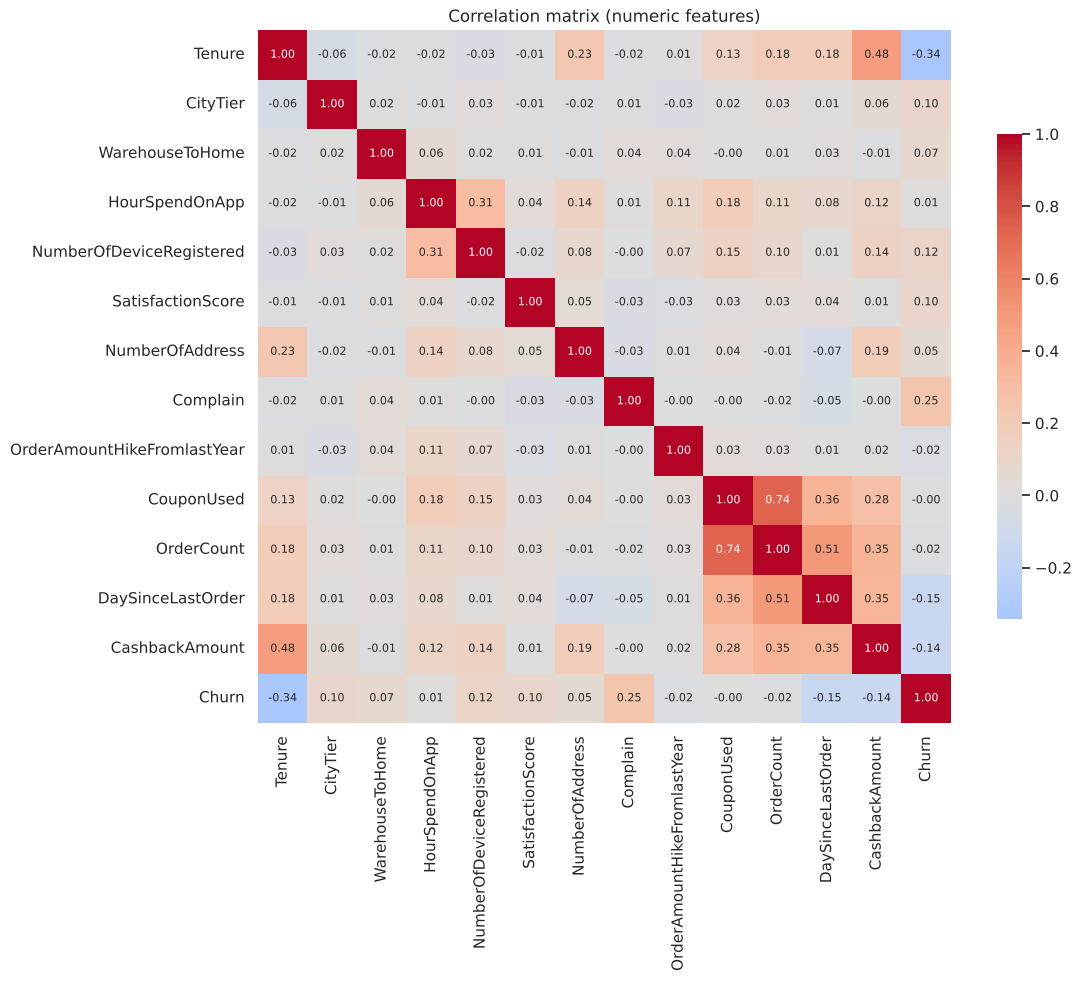

In [19]:
corr = data[NUMERIC_FEATURES + [TARGET]].corr()
plt.figure(figsize=(12, 9))
sns.heatmap(corr, annot=True, fmt=".2f", cmap="coolwarm", center=0, square=True,
            cbar_kws={"shrink": 0.7}, annot_kws={"size": 8})
plt.title("Correlation matrix (numeric features)")
plt.show()

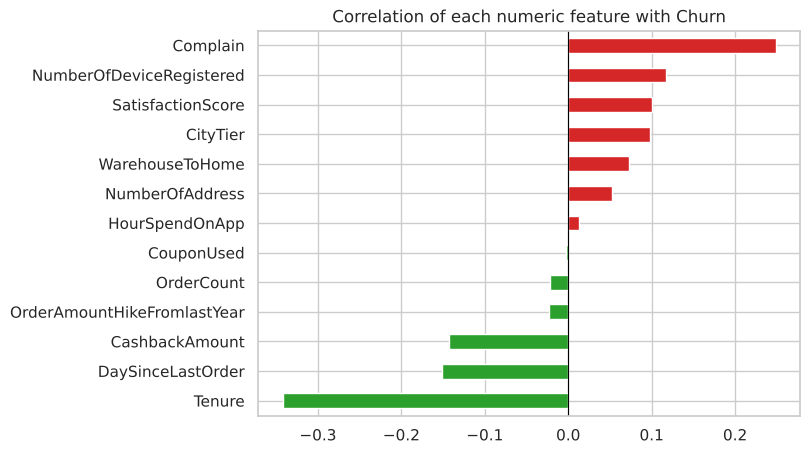

In [20]:
target_corr = corr[TARGET].drop(TARGET).sort_values()
ax = target_corr.plot(kind="barh", figsize=(7, 5),
                      color=["#2ca02c" if v < 0 else "#d62728" for v in target_corr])
ax.set_title("Correlation of each numeric feature with Churn")
ax.axvline(0, color="black", lw=0.8)
plt.show()

**Observation:** Tenure has the strongest link with churn (-0.34): longer tenure means less churn. Complain is the strongest positive link (+0.25). DaySinceLastOrder (-0.15) and CashbackAmount (-0.14) are also negatively linked. Among the features, CouponUsed and OrderCount are fairly correlated with each other (0.74), but no pair is so high that a feature must be dropped. Correlation only captures straight-line relationships, so the tree models and SHAP may find patterns this table misses.

## 8. Save the cleaned dataset

In [21]:
data.to_csv(CLEAN_DATA_PATH, index=False)
print(f"Saved {len(data):,} rows x {data.shape[1]} columns to {CLEAN_DATA_PATH.relative_to(ROOT)}")

Saved 5,073 rows x 19 columns to data/ecommerce_churn_clean.csv


## 9. Key findings

1. **Data quality:** 7 columns have about 5% missing values, 557 duplicate customers were removed, and 4 inconsistent category labels were merged. The final clean data has **5,073 customers and 18 features**.
2. **Imbalance:** only **16.6%** of customers churned, so F1-score, recall and ROC-AUC are better measures than accuracy.
3. **New customers are the biggest risk:** around half of customers in their first 1 to 2 months churn, while long-term customers almost never do.
4. **Complaints matter:** customers who complained churn about 3 times more often.
5. **Other risk signals:** single customers, Mobile Phone buyers, Cash on Delivery and E wallet users, Tier 3 cities, and lower cashback.
6. **Unexpected pattern:** higher satisfaction score goes with *more* churn in this data, which is worth noting as a limitation.

**Decisions for modelling (see `src/train.py`):**
- Missing values: median (numeric) and most-frequent (categorical) imputation inside the pipeline, fitted on training data only.
- Categorical features: one-hot encoding.
- Class imbalance: class weights (`class_weight="balanced"`, `scale_pos_weight` for XGBoost) instead of oversampling, so no synthetic customers are created.
- Outliers: kept. Tree models are robust to them and the extreme values look like real customers, not errors.
- Models: Logistic Regression (baseline), Random Forest, XGBoost, then tuned XGBoost, explained with SHAP.